# Memory retention

This case study translates the models of chapter 10 of Lee & Wagenmakers
(2013) with the PyMC adapter. The PyMC3 models come from the notebook
[MemoryRetention.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/MemoryRetention.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

For each model, the notebook:

1. ports the model to the current PyMC,
2. samples the priors in TensorFlow and runs the translated model,
3. draws the same outputs with `pm.draw`,
4. compares the two samples.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os
import warnings

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# no GPU: hide the CUDA log lines of TensorFlow
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
# pm.draw runs the truncated Normal of PyMC in Numba object mode
warnings.filterwarnings("ignore", message="Numba will use object mode")

## Imports

In [2]:
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

SEED = tf.constant([2013, 10], dtype=tf.int32)
DRAWS = 10_000

## The check

The port of a model follows the rules of the how-to guide
[Use a PyMC model][use-a-pymc-model]: each input of a
prior is a named `pm.Data` node. `adapter_pymc.parameters` reads the priors.
`sample_priors` samples each prior in TensorFlow, with the current values
of its `pm.Data` nodes.

`compare` runs the translated model on these samples. It then draws the
same outputs with `pm.draw`. For each element of an output, it computes the
Kolmogorov-Smirnov distance `D` between the two samples. The table shows
one row for each output: the element with the largest `D`, with the mean
and the standard deviation of both samples. The check fails if `D` is 0.05
or more.

PyMC computes in float64, the translated model in float32. A value near 0
or 1 then differs in the last digits. The check therefore rounds both
samples to 6 decimals, in float64.

In [3]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        prior = parameter["family"](**args)
        columns.append(prior.sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


def compare(pymc_model: Any, names: list[str], tol: float = 0.05) -> None:
    """Compare the translated model with pm.draw, for each output in names"""
    seed_priors, seed_model = tfp.random.split_seed(SEED)
    generative_model = adapter_pymc.model(pymc_model)()
    prior_samples = sample_priors(pymc_model, DRAWS, seed_priors)
    tf_out = generative_model(prior_samples, seed=seed_model)
    pm_out = pm.draw([pymc_model[name] for name in names], draws=DRAWS, random_seed=1)

    print(f"{'output':<28}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>22}{'D':>7}")
    worst = 0.0
    for name, pm_draws in zip(names, pm_out):
        tf_values = np.asarray(tf_out[name][0], dtype=float).reshape(DRAWS, -1)
        pm_values = np.asarray(pm_draws, dtype=float).reshape(DRAWS, -1)
        # round in float64: float32 cannot hold a value such as 0.873412
        tf_values, pm_values = tf_values.round(6), pm_values.round(6)
        distances = [
            stats.ks_2samp(tf_values[:, j], pm_values[:, j], method="asymp").statistic
            for j in range(tf_values.shape[1])
        ]
        j = int(np.argmax(distances))
        tf_stats, pm_stats = (
            f"{values[:, j].mean():.2f}, {values[:, j].std():.2f}"
            for values in (tf_values, pm_values)
        )
        label = f"{name}[{j}] of {tf_values.shape[1]}"
        print(f"{label:<28}{tf_stats:>22}{pm_stats:>22}{distances[j]:>7.3f}")
        worst = max(worst, distances[j])
    assert worst < tol, f"the largest distance D = {worst:.3f} is not below {tol}"

## Data

Participants study a list of items. At ten delays `t`, the data count how
many of `n = 18` items each participant still recalls. Participant 4 has no
data: the models predict the recall of this participant.

In [4]:
t = np.array([1, 2, 4, 7, 12, 21, 35, 59, 99, 200])
n = 18
k = np.array(
    [
        [18, 18, 16, 13, 9, 6, 4, 4, 4],
        [17, 13, 9, 6, 4, 4, 4, 4, 4],
        [14, 10, 6, 4, 4, 4, 4, 4, 4],
    ]
)
ns = 4  # participants, with participant 4 not observed
ns_obs, nt_obs = k.shape  # the observed participants and delays
t_obs = t[:nt_obs]

Each model predicts the recall rate `theta = exp(-alpha * t) + beta`, capped
at 1. `kij` holds the observed counts. `kij_ppc` holds the predicted counts
of all four participants at all ten delays. The upstream notebook draws
`kij_ppc` with a raw random stream; the port draws it with
`pm.Binomial.dist` inside a `pm.Deterministic`.

The upstream notebook has two versions of model 10.1. The first observes
a masked array, so PyMC imputes participant 4. The port uses the second,
which predicts participant 4 with `kij_ppc`.

In [5]:
def beta_prior(name: str, shape: Any = None) -> Any:
    """Add a Beta(1, 1) prior with pm.Data inputs to the model"""
    a = pm.Data(f"{name}_a", 1.0)
    b = pm.Data(f"{name}_b", 1.0)
    return pm.Beta(name, alpha=a, beta=b, shape=shape)


def recall(alpha: Any, beta: Any) -> None:
    """Add the recall rates, the observed counts and the predicted counts"""
    theta = pm.math.exp(-alpha[:ns_obs] * t_obs[:, None]) + beta[:ns_obs]
    thetaj = pm.Deterministic("thetaj", pm.math.clip(theta.T, 0, 1))
    pm.Binomial("kij", p=thetaj, n=n, observed=k)
    theta2 = pm.math.minimum(pm.math.exp(-alpha * t[:, None]) + beta, 1.0)
    pm.Deterministic("kij_ppc", pm.Binomial.dist(n=n, p=theta2.T))


OUTPUTS = ["thetaj", "kij", "kij_ppc"]

## 10.1 No individual differences

All participants share one `alpha` and one `beta`.

In [6]:
with pm.Model() as model1:
    alpha = beta_prior("alpha")
    beta = beta_prior("beta")
    recall(pm.math.stack([alpha] * ns), pm.math.stack([beta] * ns))

compare(model1, OUTPUTS)

output                         TensorFlow mean, sd         PyMC mean, sd      D
thetaj[2] of 27                         0.68, 0.29            0.68, 0.29  0.021
kij[2] of 27                           12.16, 5.47           12.29, 5.44  0.022


kij_ppc[32] of 40                      12.18, 5.47           12.31, 5.43  0.019


### Elicit the priors of 10.1

Give `model1` to `el.Elicit`. `elicito` reads the priors and translates
the model. `adapter_pymc.parameters` shows the priors that it reads.

In [7]:
[(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model1)]

[('alpha', 'Beta'), ('beta', 'Beta')]

Participant 4 has no data, so the expert judges this participant. The
targets are the predicted count `kij_ppc` at the delays 4, 12 and 59. For
each delay, the expert gives the median and a plausible interval, the 5 %
and the 95 % quantile. A target function receives the model output by the
name of its argument.

In [8]:
def recall_at(j: int) -> Any:
    """Return a target function that selects delay j of participant 4"""

    def target(kij_ppc: Any) -> Any:
        return kij_ppc[:, :, 3, j]

    return target


DELAYS = (2, 4, 7)  # indices of t: delays 4, 12 and 59
QUANTILES = (0.05, 0.50, 0.95)


def targets_at(delays: tuple[int, ...]) -> list[Any]:
    """Return one quantile target for each delay index"""
    return [
        el.quantiles(f"k4_t{t[j]}", output=recall_at(j), probs=QUANTILES)
        for j in delays
    ]

Three experts give the median and the 5 % and 95 % quantiles of the recalled
items of participant 4. Expert 2 gives wider intervals than expert 1 at
all three delays. Expert 3 gives the quantiles of a known prior.

| expert | delay 4 | delay 12 | delay 59 |
| :-- | :-- | :-- | :-- |
| expert 1 | 15, 16, 18 | 10, 14, 17 | 2, 9, 16 |
| expert 2 | 12, 16, 18 | 7, 14, 18 | 0, 9, 18 |
| expert 3 | 9, 17, 18 | 3, 10, 18 | 1, 4, 11 |

For each expert, CMA-ES learns the four hyperparameters. Five replications
with different seeds show whether the result depends on the seed.
`kappa` weights a spread penalty, the negative mean log standard deviation
of the priors. It keeps a prior from collapsing to a point mass.

In [9]:
def ground_truth(alpha: tuple[float, float], beta: tuple[float, float]) -> Any:
    """Return the quantiles of participant 4 under known Beta priors"""
    values = {
        "alpha_a": alpha[0],
        "alpha_b": alpha[1],
        "beta_a": beta[0],
        "beta_b": beta[1],
    }
    with model1:
        pm.set_data(values)
    counts = pm.draw(model1["kij_ppc"][3, list(DELAYS)], draws=10_000, random_seed=2013)
    with model1:
        pm.set_data({name: 1.0 for name in values})
    quantiles = np.quantile(counts, QUANTILES, axis=0).T
    return {f"k4_t{t[j]}": list(q) for j, q in zip(DELAYS, quantiles)}

In [10]:
experts = {
    "expert 1": {
        "k4_t4": [15, 16, 18],
        "k4_t12": [10, 14, 17],
        "k4_t59": [2, 9, 16],
    },
    "expert 2": {
        "k4_t4": [12, 16, 18],
        "k4_t12": [7, 14, 18],
        "k4_t59": [0, 9, 18],
    },
    "expert 3": ground_truth(alpha=(2, 18), beta=(4, 16)),
}


def elicit(quantiles: dict[str, list[int]], delays: tuple[int, ...]) -> Any:
    """Fit the priors to the expert quantiles at the given delay indices"""
    targets = targets_at(delays)
    data = {
        target["name"]: quantiles[target["name"]] for target in targets
    }
    eliobj = el.Elicit(
        model1, targets, seeds=(1, 2, 3, 4, 5), epochs=400, kappa=0.1, verbose=False
    )
    return eliobj.fit(data)


fits = {expert: elicit(quantiles, DELAYS) for expert, quantiles in experts.items()}

### Check the fit

`hyperparameters(replication=r)` returns the learned values of one
replication, by name. The loss plot shows whether the fit converged.

expert 1 0 {'alpha_b': 19.08, 'beta_b': 10.35, 'alpha_a': 2.1, 'beta_a': 8.62}
expert 1 1 {'alpha_b': 18.83, 'beta_b': 17.11, 'alpha_a': 1.94, 'beta_a': 13.67}
expert 1 2 {'alpha_b': 18.96, 'beta_b': 15.64, 'alpha_a': 1.87, 'beta_a': 11.93}
expert 1 3 {'alpha_b': 36.91, 'beta_b': 18.7, 'alpha_a': 1.98, 'beta_a': 6.8}
expert 1 4 {'alpha_b': 24.86, 'beta_b': 6.76, 'alpha_a': 2.36, 'beta_a': 5.37}
expert 2 0 {'alpha_b': 9.18, 'beta_b': 7.86, 'alpha_a': 1.11, 'beta_a': 5.65}
expert 2 1 {'alpha_b': 9.02, 'beta_b': 7.0, 'alpha_a': 1.14, 'beta_a': 5.36}
expert 2 2 {'alpha_b': 10.93, 'beta_b': 4.02, 'alpha_a': 1.24, 'beta_a': 2.84}
expert 2 3 {'alpha_b': 9.91, 'beta_b': 5.45, 'alpha_a': 1.19, 'beta_a': 3.99}
expert 2 4 {'alpha_b': 9.4, 'beta_b': 6.4, 'alpha_a': 1.14, 'beta_a': 4.62}
expert 3 0 {'alpha_b': 13.95, 'beta_b': 34.13, 'alpha_a': 1.69, 'beta_a': 8.58}
expert 3 1 {'alpha_b': 17.09, 'beta_b': 8.64, 'alpha_a': 2.18, 'beta_a': 2.69}
expert 3 2 {'alpha_b': 13.12, 'beta_b': 21.23, 'alpha_a

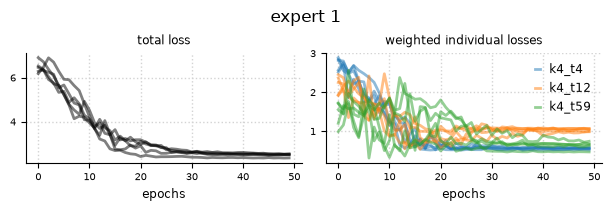

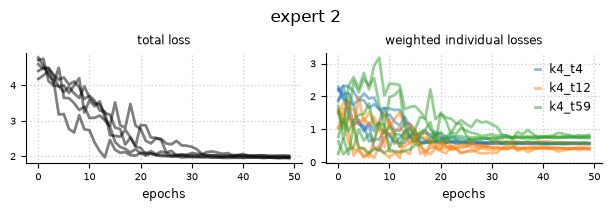

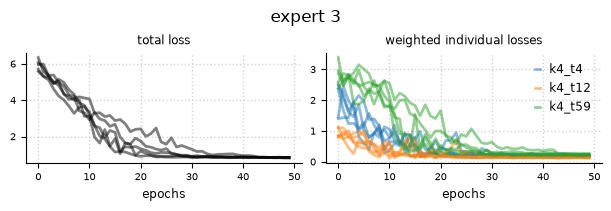

In [11]:
for expert, fit in fits.items():
    for r in range(5):
        values = fit.hyperparameters(replication=r)
        print(expert, r, {name: round(value, 2) for name, value in values.items()})
    fig, _ = fit.plot.loss()
    fig.suptitle(expert)

The validity check compares the elicited statistics with the statistics of
the expert. A point on the diagonal is a quantile that the learned priors
reproduce.

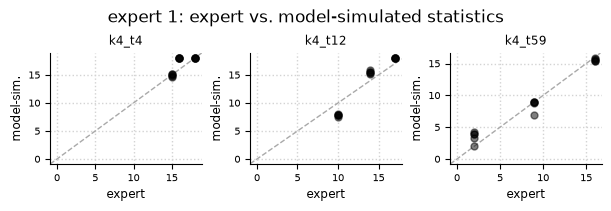

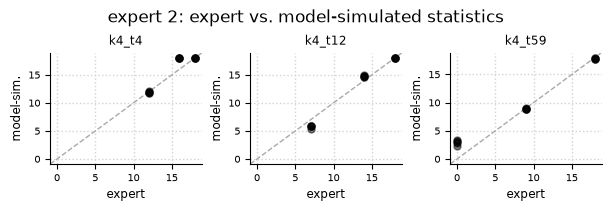

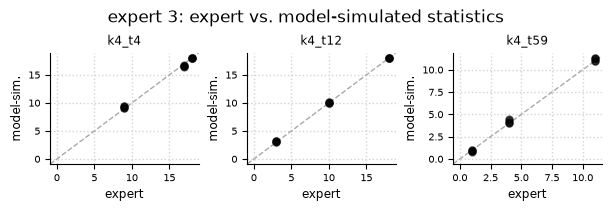

In [12]:
for expert, fit in fits.items():
    fig, _ = fit.plot.elicits()
    fig.suptitle(f"{expert}: expert vs. model-simulated statistics")

The learned priors of all experts.

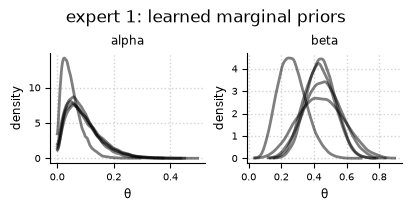

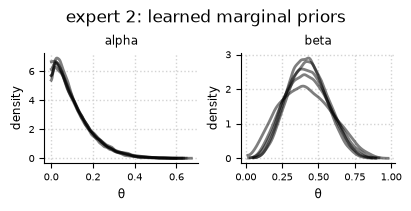

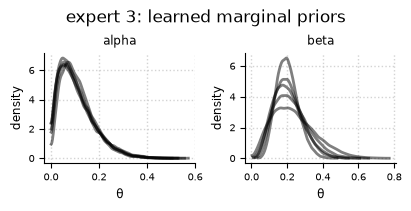

In [13]:
for expert, fit in fits.items():
    fig, _ = fit.plot.prior_marginals()
    fig.suptitle(f"{expert}: learned marginal priors")

### Back to PyMC

`model1` observes the counts `k`. We sample the posterior first with the
Beta(1, 1) priors. For each expert, `set_hyperparameters` then writes the
learned values of replication 0 into the `pm.Data` nodes, and we sample
again. The model gives divergences at the default `target_accept`, with
any prior, so all runs use 0.95.

Where `exp(-alpha * t) + beta` exceeds 1, `clip` sets the rate to 1, and
the observed counts below 18 have zero probability. The elicited priors put
mass there, so a random start can fail. `INITVALS` starts every chain in
the region of the posterior.

In [14]:
INITVALS = {"alpha": 0.3, "beta": 0.2}


def sample(fit: Any = None) -> tuple[Any, Any]:
    """Return prior and posterior draws, with the priors of fit if given"""
    if fit is not None:
        adapter_pymc.set_hyperparameters(model1, fit, replication=0)
    prior = pm.sample_prior_predictive(draws=2_000, random_seed=2013, model=model1)
    post = pm.sample(
        500,
        tune=500,
        chains=4,
        target_accept=0.95,
        initvals=INITVALS,
        random_seed=2013,
        model=model1,
    )
    return prior, post


runs = {"Beta(1, 1)": sample()}
for expert, fit in fits.items():
    runs[expert] = sample(fit)

for run, (_, post) in runs.items():
    s = post.posterior.to_dataset()[["alpha", "beta"]].mean(("chain", "draw"))
    print(run, {v: round(float(s[v]), 3) for v in ("alpha", "beta")})

Sampling: [alpha, beta, kij]


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta]


Output()

Sampling 4 chains for 500 tune and 500 draw iterations (2_000 + 2_000 draws total) took 2 seconds.


... (22 outputs left out)

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Beta(1, 1) {'alpha': 0.349, 'beta': 0.24}
expert 1 {'alpha': 0.323, 'beta': 0.231}
expert 2 {'alpha': 0.334, 'beta': 0.235}
expert 3 {'alpha': 0.302, 'beta': 0.214}


The priors and posteriors of all runs. The rows are the runs, the columns
the parameters. All panels share the x-scale.

(0.0, 1.0)

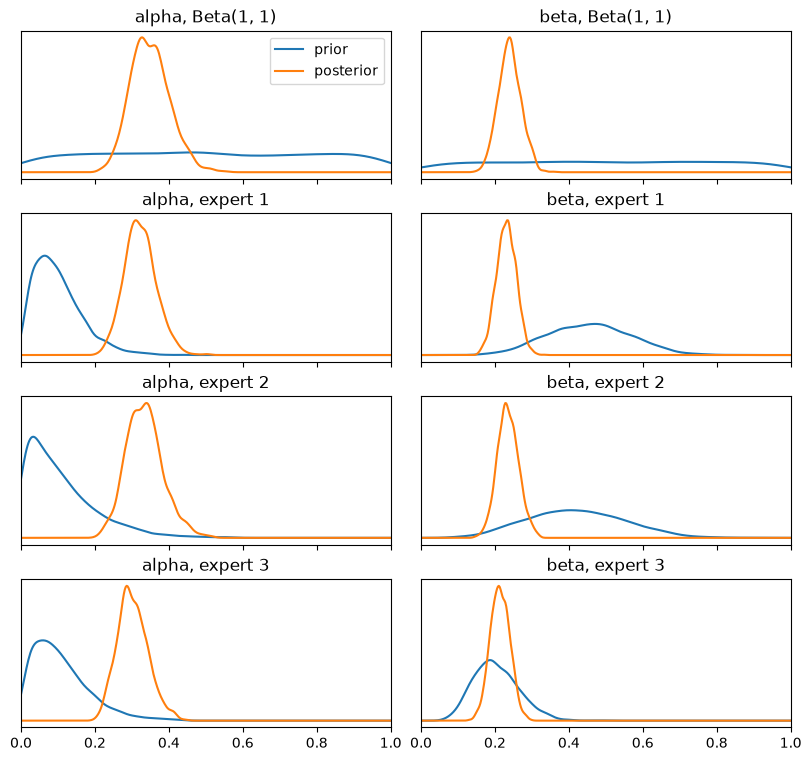

In [15]:
grid = np.linspace(0, 1, 400)
fig, axes = plt.subplots(
    len(runs), 2, figsize=(8, 7.5), sharex=True, constrained_layout=True
)
for row, (run, (prior, post)) in zip(axes, runs.items()):
    for ax, name in zip(row, ["alpha", "beta"]):
        for label, idata, group in [
            ("prior", prior, "prior"),
            ("posterior", post, "posterior"),
        ]:
            values = idata[group].to_dataset()[name].values.ravel()
            ax.plot(grid, stats.gaussian_kde(values)(grid), label=label)
        ax.set_title(f"{name}, {run}")
        ax.set_yticks([])
axes[0, 0].legend()
axes[-1, 0].set_xlim(0, 1)

## 10.2 Full individual differences

Each participant has an own `alpha` and `beta`. A prior with four elements
becomes four parameters, `alpha[0]` to `alpha[3]`, with shared
hyperparameters.

In [16]:
with pm.Model() as model2:
    recall(beta_prior("alpha", shape=ns), beta_prior("beta", shape=ns))

compare(model2, OUTPUTS)

output                         TensorFlow mean, sd         PyMC mean, sd      D
thetaj[21] of 27                        0.60, 0.30            0.61, 0.30  0.024
kij[22] of 27                          10.01, 5.73           10.20, 5.66  0.022


kij_ppc[29] of 40                       8.94, 5.49            9.14, 5.46  0.022


## 10.3 Structured individual differences

The participant parameters come from group distributions: a Normal
truncated to [0, 1], with a Beta prior on the mean and a Gamma prior on the
precision. The participant parameters have no `pm.Data` input, so the
translated model samples them.

The book gives the precisions a `Gamma(0.001, 0.001)` prior. Most of its
draws underflow to 0, and `pm.draw` then fails: the scale of the truncated
Normal is not finite. The check therefore sets `Gamma(2, 2)` with
`pm.set_data`. The translation does not depend on these values.

In [17]:
def gamma_prior(name: str) -> Any:
    """Add a Gamma(0.001, 0.001) prior with pm.Data inputs to the model"""
    alpha = pm.Data(f"{name}_alpha", 0.001)
    beta = pm.Data(f"{name}_beta", 0.001)
    return pm.Gamma(name, alpha=alpha, beta=beta)


with pm.Model() as model3:
    mua, lambdaa = beta_prior("mua"), gamma_prior("lambdaa")
    mub, lambdab = beta_prior("mub"), gamma_prior("lambdab")
    alpha = pm.TruncatedNormal(
        "alpha", mu=mua, sigma=1 / pm.math.sqrt(lambdaa), lower=0, upper=1, shape=ns
    )
    beta = pm.TruncatedNormal(
        "beta", mu=mub, sigma=1 / pm.math.sqrt(lambdab), lower=0, upper=1, shape=ns
    )
    recall(alpha, beta)

pm.set_data(
    {
        "lambdaa_alpha": 2.0,
        "lambdaa_beta": 2.0,
        "lambdab_alpha": 2.0,
        "lambdab_beta": 2.0,
    },
    model=model3,
)
compare(model3, OUTPUTS)

output                         TensorFlow mean, sd         PyMC mean, sd      D
thetaj[21] of 27                        0.61, 0.30            0.60, 0.30  0.017
kij[5] of 27                            9.61, 5.52            9.61, 5.60  0.016


kij_ppc[6] of 40                        9.36, 5.47            9.40, 5.54  0.014


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.